# A combined bus + rail network for London

The rail analysis studied the TfL rail network on its own. This notebook adds the bus network
(BUSTO 2025-26 weekday routes) and asks:

1. **Accessibility:** how long does it take to reach the rest of the network from each place, and
   where does rail make the biggest difference?
2. **Centrality:** which rail stations matter most once buses are counted?
3. **Resilience:** how much do buses soften rail station closures, and which bus routes does the
   network depend on?

**Network.** Nodes are bus **stop areas** (stops on both sides of the road; 10,273) and TfL rail
**stations** (418; no trams, as in the rail analysis). Edges join consecutive stop areas on each bus
route, adjacent stations on each rail line, and stop areas to stations within 400 m (walking links).

**Edge weights are estimated travel times**, because hop counts are not comparable between modes
(a bus passes many more stops per kilometre than a train):

| Edge | Time |
|---|---|
| bus | road distance (1.3 x straight line) at 15 km/h, at least 0.5 min |
| rail | straight-line distance at 30 km/h, at least 1 min |
| walk (bus <-> rail) | 1.3 x straight line at 4.8 km/h, **plus 5 min** to change mode |

Waiting for the first vehicle and changes between bus routes or rail lines are not modelled (as in
the rail analysis); the sensitivity section varies the speeds and the change penalty.

In [1]:
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.sparse.csgraph import dijkstra
from scipy.stats import spearmanr

import tfl_analysis as T
import tfl_bus as B

B.RESULTS.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(2024)

G = B.build_bus_rail_graph()                         # bus + rail
G_bus = B.build_bus_rail_graph(include_rail=False)   # bus only
G_rail = B.build_bus_rail_graph(include_bus=False)   # rail only, same travel-time weights
rail_nodes = [n for n in G if n.startswith('rail:')]
bus_nodes = [n for n in G if n.startswith('bus:')]

def describe(H):
    modes = pd.Series([d['mode'] for *_, d in H.edges(data=True)]).value_counts()
    return {'nodes': H.number_of_nodes(), 'edges': H.number_of_edges(), **modes.to_dict(),
            'components': nx.number_connected_components(H)}
pd.DataFrame({'bus + rail': describe(G), 'bus only': describe(G_bus), 'rail only': describe(G_rail)}).fillna(0).astype(int)

,bus + rail,bus only,rail only
nodes,10691,10273,418
edges,17615,14673,496
bus,14673,14673,0
walk,2446,0,0
rail,496,0,496
components,1,1,1


## 1. Accessibility: mean travel time to everywhere else

In [2]:
def mean_time(H, targets=None):
    '''Mean travel time (min) from each node to every node in `targets` (default: all).'''
    nodes = list(H)
    A = nx.to_scipy_sparse_array(H, nodelist=nodes, weight='minutes', format='csr')
    tgt = np.arange(len(nodes)) if targets is None else np.array([nodes.index(t) for t in targets])
    out = np.empty(len(nodes))
    for chunk in np.array_split(np.arange(len(nodes)), max(1, len(nodes) // 500)):
        D = dijkstra(A, directed=False, indices=chunk)[:, tgt]
        out[chunk] = np.where(np.isfinite(D), D, np.nan).mean(axis=1)
    return pd.Series(out, index=nodes)

t0 = time.time()
acc = pd.DataFrame({'bus + rail': mean_time(G, bus_nodes), 'bus only': mean_time(G_bus, bus_nodes)})
acc['saved by rail'] = acc['bus only'] - acc['bus + rail']
pos = pd.DataFrame({n: (G.nodes[n]['lon'], G.nodes[n]['lat']) for n in G}, index=['lon', 'lat']).T
print(f"computed in {time.time() - t0:.0f}s. Mean travel time from a bus stop area to all others: "
      f"{acc.loc[bus_nodes, 'bus + rail'].mean():.0f} min with rail, {acc.loc[bus_nodes, 'bus only'].mean():.0f} min by bus only")
acc.loc[bus_nodes].describe(percentiles=[.1, .5, .9]).round(1)

computed in 24s. Mean travel time from a bus stop area to all others: 79 min with rail, 116 min by bus only


,bus + rail,bus only,saved by rail
count,10273.0,10273.0,10273.0
mean,79.2,116.2,37.0
std,18.6,25.4,12.5
min,52.2,78.7,20.9
10%,59.1,86.6,24.8
50%,76.1,112.3,33.7
90%,103.4,151.2,54.7
max,205.6,234.1,95.1


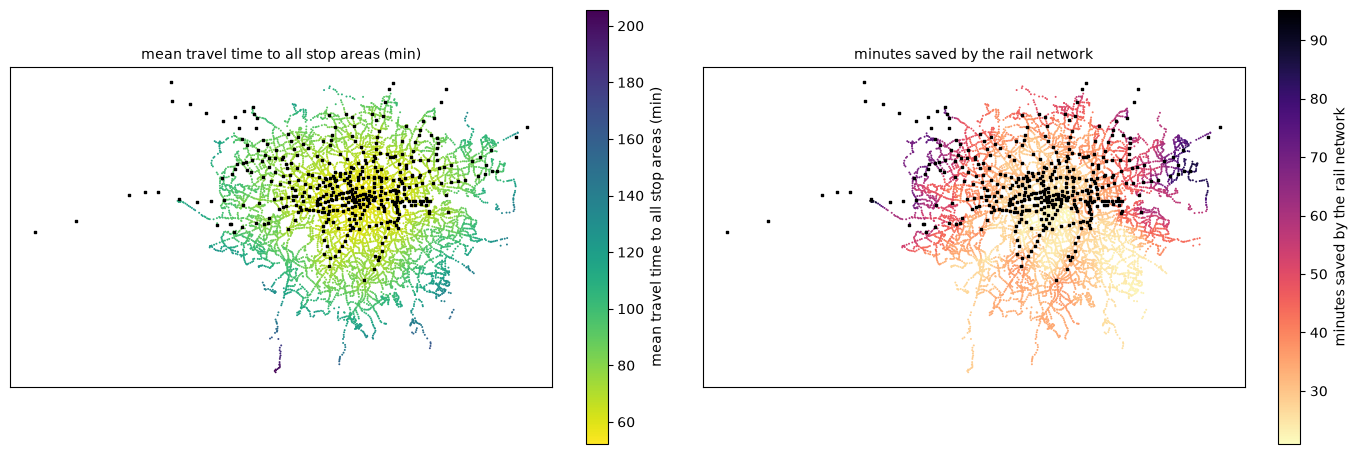

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
b = acc.loc[bus_nodes].join(pos)
for ax, col, cmap, label in [(axs[0], 'bus + rail', 'viridis_r', 'mean travel time to all stop areas (min)'),
                             (axs[1], 'saved by rail', 'magma_r', 'minutes saved by the rail network')]:
    sc = ax.scatter(b.lon, b.lat, c=b[col], cmap=cmap, s=2, lw=0)
    plt.colorbar(sc, ax=ax, shrink=.7, label=label)
    ax.set_aspect(1 / np.cos(np.radians(51.5))); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(label, fontsize=10)
r = pos.loc[rail_nodes]
for ax in axs:
    ax.scatter(r.lon, r.lat, s=3, color='black', marker='s')
plt.tight_layout(); plt.show()

In [4]:
# Where does rail save least / most? By distance from the centre
b['from_centre'] = pd.cut(B.haversine_m(b.lat, b.lon, 51.5080, -0.1246) / 1000, [0, 3, 6, 10, 15, 50],
                          labels=['0-3 km', '3-6 km', '6-10 km', '10-15 km', '15+ km'])
linked = pd.read_parquet(B.PROCESSED / 'bus-stops-linked.parquet')
stops = B.load_stops()
area_dist = linked.assign(node=lambda d: 'bus:' + d.stop_area).groupby('node').dist_m.min()
b['to_rail'] = pd.cut(area_dist.reindex(b.index), [0, 400, 800, 2000, np.inf], right=False,
                      labels=['< 400 m', '400-800 m', '800 m - 2 km', '> 2 km'])
acc_tab = pd.concat({
    'from centre': b.groupby('from_centre', observed=True)[['bus + rail', 'bus only', 'saved by rail']].mean(),
    'to TfL rail': b.groupby('to_rail', observed=True)[['bus + rail', 'bus only', 'saved by rail']].mean(),
}).round(1)
acc_tab.to_csv(B.RESULTS / 'network_accessibility.csv')
acc_tab

bus + rail  bus only  saved by rail
from centre 0-3 km              55.6      80.6           25.0
            3-6 km              59.1      85.8           26.7
            6-10 km             64.4      93.9           29.5
            10-15 km            73.7     108.3           34.6
            15+ km              95.4     140.3           44.9
to TfL rail < 400 m             64.6     100.4           35.9
            400-800 m           69.6     106.8           37.3
            800 m - 2 km        77.8     117.9           40.1
            > 2 km              98.7     133.3           34.6

## 2. Which rail stations matter most once buses are counted?

**Betweenness** (share of quickest journeys passing through a node), computed exactly on travel
times for the combined network and for the rail network alone (same rail travel times).

In [5]:
t0 = time.time()
bc = pd.Series(nx.betweenness_centrality(G, weight='minutes'))
bc_rail = pd.Series(nx.betweenness_centrality(G_rail, weight='minutes'))
print(f"betweenness computed in {time.time() - t0:.0f}s")

top_all = bc.nlargest(15).rename('betweenness').to_frame()
top_all['type'] = [G.nodes[n]['mode'] for n in top_all.index]
top_all['name'] = [G.nodes[n]['name'].title() if G.nodes[n]['mode'] == 'bus' else G.nodes[n]['name'] for n in top_all.index]
print(f"share of all betweenness on rail stations: {100 * bc[rail_nodes].sum() / bc.sum():.0f}% "
      f"({len(rail_nodes)} of {len(G)} nodes)")
top_all[['name', 'type', 'betweenness']].round(4)

betweenness computed in 300s
share of all betweenness on rail stations: 48% (418 of 10691 nodes)


,name,type,betweenness
rail:Canada Water,Canada Water,rail,0.2133
rail:London Bridge,London Bridge,rail,0.1816
rail:Surrey Quays,Surrey Quays,rail,0.1716
rail:Earl's Court,Earl's Court,rail,0.1716
rail:Liverpool Street,Liverpool Street,rail,0.1670
rail:Bank and Monument,Bank and Monument,rail,0.1564
rail:New Cross Gate,New Cross Gate,rail,0.1554
rail:Waterloo,Waterloo,rail,0.1547
rail:South Kensington,South Kensington,rail,0.1535
rail:Brockley,Brockley,rail,0.1515


In [6]:
rs = pd.DataFrame({'bus + rail': bc[rail_nodes], 'rail only': bc_rail.reindex(rail_nodes)})
rs.index = rs.index.str[5:]
rs['rank, bus + rail'] = rs['bus + rail'].rank(ascending=False, method='min').astype(int)
rs['rank, rail only'] = rs['rail only'].rank(ascending=False, method='min').astype(int)
rs['rank change'] = rs['rank, rail only'] - rs['rank, bus + rail']
rs['walking links to bus'] = [sum(1 for nb in G['rail:' + s] if nb.startswith('bus:')) for s in rs.index]
rs.to_csv(B.RESULTS / 'network_rail_station_betweenness.csv', index_label='station')
rho = spearmanr(rs['bus + rail'], rs['rail only']).statistic
print(f"Spearman correlation of station betweenness, combined vs rail only: {rho:.2f}")
rs.sort_values('rank, bus + rail').head(15)[['rank, bus + rail', 'rank, rail only', 'rank change', 'walking links to bus']]

Spearman correlation of station betweenness, combined vs rail only: 0.74


,"rank, bus + rail","rank, rail only",rank change,walking links to bus
Canada Water,1,29,28,9
London Bridge,2,30,28,6
Surrey Quays,3,53,50,8
Earl's Court,4,7,3,8
Liverpool Street,5,2,-3,9
Bank and Monument,6,4,-2,10
New Cross Gate,7,113,106,7
Waterloo,8,10,2,11
South Kensington,9,11,2,14
Brockley,10,129,119,4


In [7]:
print('Biggest risers (stations that become more central once buses are added):')
display(rs.sort_values('rank change', ascending=False).head(8)[['rank, rail only', 'rank, bus + rail', 'walking links to bus']])
print('Biggest fallers:')
rs.sort_values('rank change').head(8)[['rank, rail only', 'rank, bus + rail', 'walking links to bus']]

Biggest risers (stations that become more central once buses are added):


,"rank, rail only","rank, bus + rail",walking links to bus
West Croydon,379,80,10
Norwood Junction,335,41,9
Woolwich,335,48,8
Abbey Wood,379,94,9
Lewisham,379,113,10
Anerley,299,34,9
Richmond,379,117,9
Kew Gardens,335,99,4


Biggest fallers:


,"rank, rail only","rank, bus + rail",walking links to bus
Moor Park,150,385,0
Iver,151,351,0
Northwood,129,321,4
Northwood Hills,113,295,7
Langley,175,354,0
Rickmansworth,221,395,0
Burnham,221,395,0
Pinner,101,271,4


## 3. Resilience

### 3a. Closing rail stations: do buses soften the blow?

Close the most central rail stations one by one (highest rail-only betweenness, recomputed after each
closure) and measure **efficiency between the remaining rail stations**: the mean of 1 / travel time
over station pairs (unreachable pairs count as 0). In the rail-only network a closure can cut
journeys; in the combined network passengers can switch to buses around it.

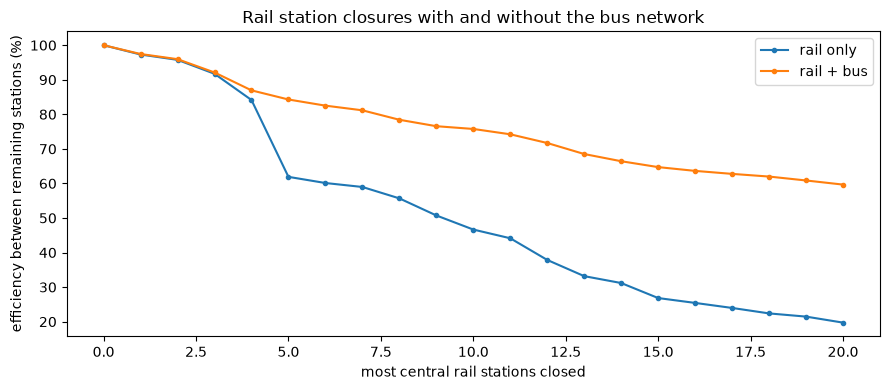

,stations closed,rail only,bus + rail,station closed
1,1,0.973,0.975,King's Cross St. Pancras
5,5,0.619,0.843,West Hampstead
10,10,0.467,0.758,Ealing Common
20,20,0.197,0.597,Victoria


In [8]:
def rail_pair_efficiency(H, stations):
    nodes = list(H)
    idx = {n: i for i, n in enumerate(nodes)}
    st = [idx[s] for s in stations if s in idx]
    A = nx.to_scipy_sparse_array(H, nodelist=nodes, weight='minutes', format='csr')
    D = dijkstra(A, directed=False, indices=st)[:, st]
    np.fill_diagonal(D, np.inf)
    return (1 / D).sum() / (len(st) * (len(st) - 1))

MAX_CLOSED = 20
Hr, Hc = G_rail.copy(), G.copy()
base_r, base_c = rail_pair_efficiency(Hr, rail_nodes), rail_pair_efficiency(Hc, rail_nodes)
curve, closed = [(0, 1.0, 1.0, '')], []
for k in range(1, MAX_CLOSED + 1):
    b_ = nx.betweenness_centrality(Hr, weight='minutes')
    s = max(b_, key=lambda n: (b_[n], n))
    Hr.remove_node(s); Hc.remove_node(s); closed.append(s)
    remaining = [n for n in rail_nodes if n not in closed]
    curve.append((k, rail_pair_efficiency(Hr, remaining) / base_r,
                  rail_pair_efficiency(Hc, remaining) / base_c, s[5:]))
curve = pd.DataFrame(curve, columns=['stations closed', 'rail only', 'bus + rail', 'station closed'])
curve.to_csv(B.RESULTS / 'network_rail_closures.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve['stations closed'], 100 * curve['rail only'], 'o-', ms=3, label='rail only')
ax.plot(curve['stations closed'], 100 * curve['bus + rail'], 'o-', ms=3, label='rail + bus')
ax.set_xlabel('most central rail stations closed'); ax.set_ylabel('efficiency between remaining stations (%)')
ax.set_title('Rail station closures with and without the bus network'); ax.legend(); plt.tight_layout(); plt.show()
curve.iloc[[1, 5, 10, 20]].round(3)

### 3b. Which bus routes does the network depend on?

Remove one bus route at a time (edges served only by that route disappear; shared edges stay) and
measure the loss in network efficiency (mean 1 / travel time from 500 random origins to everywhere),
and how many stop areas lose their only connection.

In [9]:
sample = list(rng.choice(list(G), 500, replace=False))
base_eff = B.efficiency_minutes(G, sources=sample)
edges_by_route = {}
for a, c, d in G.edges(data=True):
    for r in d.get('routes', ()):
        edges_by_route.setdefault(r, []).append((a, c))

t0 = time.time()
rows = []
for r, es in edges_by_route.items():
    H = G.copy()
    for a, c in es:
        H[a][c]['routes'] = H[a][c]['routes'] - {r}
        if not H[a][c]['routes']:
            H.remove_edge(a, c)
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    cut = sum(len(c) for c in comps[1:])
    rows.append({'route': r, 'type': B.route_type(r), 'edges': len(es),
                 'efficiency loss (%)': 100 * (1 - B.efficiency_minutes(H, sources=sample) / base_eff),
                 'stop areas cut off': cut})
routes_crit = pd.DataFrame(rows).set_index('route').sort_values('efficiency loss (%)', ascending=False)
routes_crit.round(3).to_csv(B.RESULTS / 'network_critical_bus_routes.csv')
print(f"{len(routes_crit)} routes in {time.time() - t0:.0f}s; "
      f"{(routes_crit['stop areas cut off'] > 0).sum()} routes are the only link for at least one stop area")
routes_crit.head(15).round(3)

606 routes in 425s; 388 routes are the only link for at least one stop area


,type,edges,efficiency loss (%),stop areas cut off
route,,,,
H28,letter prefix,72,0.998,39
P5,letter prefix,54,0.970,23
336,numbered,62,0.801,25
450,numbered,59,0.785,23
394,numbered,46,0.743,16
352,numbered,45,0.710,21
C11,letter prefix,72,0.676,16
200,numbered,47,0.619,23
51,numbered,75,0.590,22


In [10]:
# Stop areas served by a single route and far from rail: where people depend on one bus route
area_routes = {n: set().union(*[d.get('routes', set()) for *_, d in G.edges(n, data=True)]) for n in bus_nodes}
single = pd.Series({n: len(r) == 1 for n, r in area_routes.items()})
w = linked.assign(node=lambda d: 'bus:' + d.stop_area).groupby('node').weekday_boardings.sum()
dep = pd.DataFrame({'single_route': single, 'boardings': w.reindex(single.index).fillna(0),
                    'to_rail': b['to_rail']})
tab = dep.groupby('to_rail', observed=True).apply(lambda g: pd.Series({
    'stop areas': len(g), 'served by one route (%)': 100 * g.single_route.mean(),
    'boardings at one-route stop areas (%)': 100 * g.boardings[g.single_route].sum() / g.boardings.sum()}),
    include_groups=False).round(1)
tab.to_csv(B.RESULTS / 'network_single_route_dependency.csv')
print(f"{single.sum():,} of {len(single):,} stop areas ({100 * single.mean():.0f}%) are served by one route")
tab

3,781 of 10,273 stop areas (37%) are served by one route


,stop areas,served by one route (%),boardings at one-route stop areas (%)
to_rail,,,
< 400 m,2268.0,21.2,2.6
400-800 m,2150.0,34.0,8.5
800 m - 2 km,2867.0,40.3,13.3
> 2 km,2988.0,47.3,13.4


## 4. Sensitivity to the travel-time assumptions

Rail-station betweenness ranks under different assumptions (sampled betweenness from 1,500 origins,
which is close to exact: see the first row), compared with the main specification.

In [11]:
variants = {
    'main (sampled)': {},
    'bus 12 km/h': dict(bus_kmh=12),
    'bus 18 km/h': dict(bus_kmh=18),
    'rail 25 km/h': dict(rail_kmh=25),
    'change penalty 2 min': dict(change_min=2),
    'change penalty 10 min': dict(change_min=10),
    'walking links up to 200 m': dict(walk_m=200),
}
main_top10 = set(rs.nsmallest(10, 'rank, bus + rail').index)
rows = {}
for name, kw in variants.items():
    H = B.build_bus_rail_graph(**kw)
    bv = pd.Series(nx.betweenness_centrality(H, k=1500, weight='minutes', seed=7))
    bv = bv[[n for n in bv.index if n.startswith('rail:')]]
    bv.index = bv.index.str[5:]
    top10 = set(bv.nlargest(10).index)
    rows[name] = {'Spearman vs main': round(spearmanr(bv.reindex(rs.index), rs['bus + rail']).statistic, 3),
                  'top-10 overlap with main': len(top10 & main_top10),
                  'top 5': ', '.join(bv.nlargest(5).index)}
sens = pd.DataFrame(rows).T
sens.to_csv(B.RESULTS / 'network_sensitivity.csv')
sens

,Spearman vs main,top-10 overlap with main,top 5
main (sampled),0.997,9,"Canada Water, London Bridge, Surrey Quays, Ear..."
bus 12 km/h,0.995,8,"Canada Water, London Bridge, Surrey Quays, Ear..."
bus 18 km/h,0.989,9,"Canada Water, Surrey Quays, London Bridge, Ear..."
rail 25 km/h,0.971,9,"Canada Water, Surrey Quays, London Bridge, Ear..."
change penalty 2 min,0.997,9,"Canada Water, London Bridge, Surrey Quays, Ear..."
change penalty 10 min,0.997,10,"Canada Water, London Bridge, Surrey Quays, Ear..."
walking links up to 200 m,0.996,9,"Canada Water, London Bridge, Surrey Quays, Ear..."


## Summary

* **Rail cuts average journey times by about a third.** From a typical bus stop
  area, the mean estimated travel time to all others is 79 min using bus + rail against 116 min by bus
  alone. Rail saves most in outer London (45 min beyond 15 km from the centre, 25 min within 3 km) and
  least in south London, where TfL rail is sparse.
* **Adding buses reshapes which rail stations are central** (Spearman 0.74 with the rail-only ranking).
  The top stations become those where large bus catchments meet fast rail: Canada Water, London Bridge,
  Surrey Quays, Earl's Court, Liverpool Street, Bank and Monument. Stations on the Overground line through
  south-east London (New Cross Gate, Brockley, Honor Oak Park, Forest Hill) jump 100-160 places, and bus
  interchanges at the edge of the rail network rise (West Croydon, Norwood Junction, Woolwich, Abbey Wood,
  Lewisham). Stations beyond the bus network fall (Moor Park, Rickmansworth, Iver, Burnham).
* **Caveat: TfL rail only.** National Rail is not in the network, so in south London, where most rail
  is National Rail, the Overground line is the only fast route in the model and attracts a large share
  of quickest journeys. With National Rail included its role would likely be smaller.
* **Buses make rail closures much less damaging.** Closing the 10 most central rail stations leaves 47%
  of the efficiency between the remaining stations in the rail-only network, but 76% when passengers
  can use buses around them (20 closures: 20% vs 60%).
* **No single bus route is critical for the network as a whole** (the largest loss from removing one
  route is 1%), but **388 of 606 routes are the only link for at least one stop area**, and 37% of stop
  areas are served by one route: 21% within 400 m of rail, 47% more than 2 km away. Routes such as H28,
  P5, 336 and 450 each leave 20-40 stop areas cut off.
* **Robust to the assumptions:** station rankings barely change with bus speed 12-18 km/h, rail
  25 km/h, a change penalty of 2-10 min or 200 m walking links (Spearman 0.97-1.00 with the main result).

The model has no timetable: waiting for the first vehicle and changes between bus routes or rail
lines are free, so travel times are best read as relative rather than absolute.